# 05 — Delivery model evaluation

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
df = pd.read_csv(ROOT/"data/processed/delivery_features.csv")
y = df.pop("target_delivery_minutes"); X = df
num = X.select_dtypes(include=["number"]).columns.tolist()
cat = [c for c in X.columns if c not in num]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)
prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", keep_empty_features=True), num),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=5))]), cat)
])
model = Pipeline([("preprocess", prep), ("model", ExtraTreesRegressor(
    n_estimators=100, min_samples_leaf=2, max_features=0.9, n_jobs=-1, random_state=42
))])
model.fit(X_train, y_train)
pred = np.clip(model.predict(X_valid), 1, 180)
# Regression metrics on the held-out validation set
mae = mean_absolute_error(y_valid, pred)
rmse = mean_squared_error(y_valid, pred) ** 0.5
r2 = r2_score(y_valid, pred)

# Adjusted R² uses the number of columns after the fitted preprocessing step.
# Note: adjusted R² was developed mainly for linear regression. For tree
# ensembles such as ExtraTrees, report MAE/RMSE/R² as the primary metrics and
# treat adjusted R² as a supplementary descriptive statistic.
n = len(y_valid)
X_valid_transformed = model.named_steps["preprocess"].transform(X_valid)
p = X_valid_transformed.shape[1]

if n > p + 1:
    adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
else:
    adjusted_r2 = np.nan

print("Delivery Model Evaluation")
print(f"MAE:          {mae:.3f} minutes")
print(f"RMSE:         {rmse:.3f} minutes")
print(f"R²:           {r2:.4f}")
print(f"Adjusted R²:  {adjusted_r2:.4f}" if np.isfinite(adjusted_r2)
      else "Adjusted R²: undefined (validation rows must exceed predictors + 1)")

metrics = pd.DataFrame([{
    "MAE_minutes": mae,
    "RMSE_minutes": rmse,
    "R2": r2,
    "Adjusted_R2": adjusted_r2,
    "validation_rows": n,
    "predictor_columns_before_encoding": p,
}])
metrics_path = ROOT / "reports" / "delivery_model_metrics.csv"
metrics_path.parent.mkdir(parents=True, exist_ok=True)
metrics.to_csv(metrics_path, index=False)
print(f"Saved metrics to: {metrics_path}")

Delivery Model Evaluation
MAE:          3.458 minutes
RMSE:         4.361 minutes
R²:           0.7831
Adjusted R²:  0.7823
Saved metrics to: /Users/kakulrajput/Documents/food-ordering-delivery-ml/reports/delivery_model_metrics.csv


In [2]:
evaluation = pd.DataFrame({
    "actual_minutes": y_valid,
    "predicted_minutes": pred
})
evaluation["error_minutes"] = evaluation["predicted_minutes"] - evaluation["actual_minutes"]
evaluation["absolute_error_minutes"] = evaluation["error_minutes"].abs()
display(evaluation.head(10))
display(evaluation["absolute_error_minutes"].describe())

,actual_minutes,predicted_minutes,error_minutes,absolute_error_minutes
7725,44,43.272500,-0.727500,0.727500
949,41,37.558333,-3.441667,3.441667
44893,39,35.783333,-3.216667,3.216667
42071,38,37.283333,-0.716667,0.716667
27091,38,36.990000,-1.010000,1.010000
18398,22,20.815000,-1.185000,1.185000
13996,14,16.528333,2.528333,2.528333
10192,17,23.418333,6.418333,6.418333
8565,22,21.168333,-0.831667,0.831667
15253,29,24.301667,-4.698333,4.698333


count    9.119000e+03
mean     3.457700e+00
std      2.657266e+00
min      3.552714e-15
25%      1.435000e+00
50%      2.922500e+00
75%      4.803333e+00
max      2.231917e+01
Name: absolute_error_minutes, dtype: float64

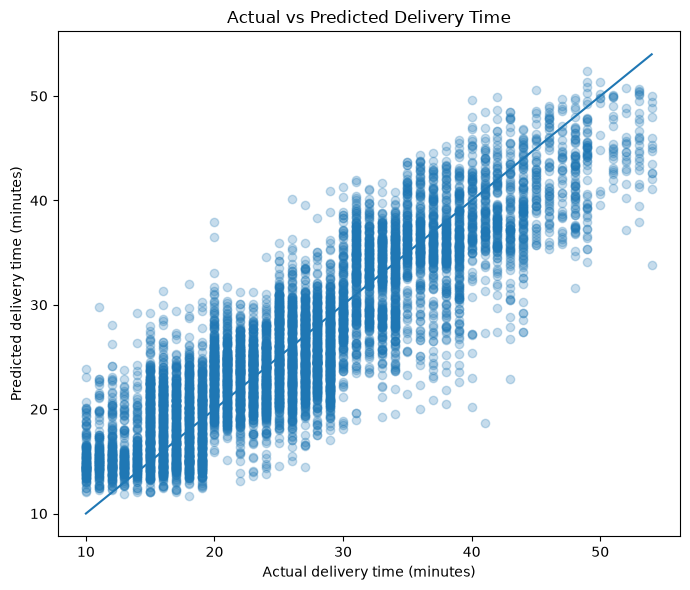

In [3]:
plt.figure(figsize=(7, 6))
plt.scatter(evaluation["actual_minutes"], evaluation["predicted_minutes"], alpha=0.25)
lo = min(evaluation["actual_minutes"].min(), evaluation["predicted_minutes"].min())
hi = max(evaluation["actual_minutes"].max(), evaluation["predicted_minutes"].max())
plt.plot([lo, hi], [lo, hi])
plt.xlabel("Actual delivery time (minutes)")
plt.ylabel("Predicted delivery time (minutes)")
plt.title("Actual vs Predicted Delivery Time")
plt.tight_layout()
plt.show()

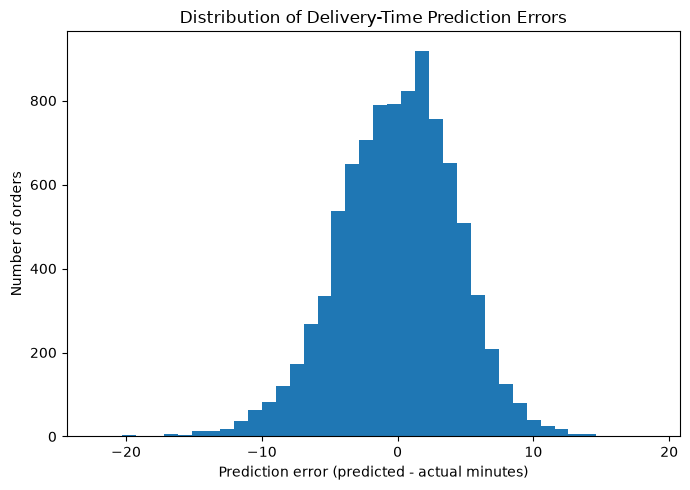

Saved validation predictions.


In [4]:
plt.figure(figsize=(7, 5))
plt.hist(evaluation["error_minutes"], bins=40)
plt.xlabel("Prediction error (predicted - actual minutes)")
plt.ylabel("Number of orders")
plt.title("Distribution of Delivery-Time Prediction Errors")
plt.tight_layout()
plt.show()

evaluation.to_csv(ROOT/"reports/delivery_validation_predictions.csv", index=False)
print("Saved validation predictions.")